In [1]:
import os
import pandas as pd 
import numpy as np
import warnings
from pathlib import Path 

import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.backends.backend_pdf import PdfPages

from neuron_morphology.swc_io import morphology_from_swc
from morph_utils.visuals import basic_morph_plot
from morph_utils.measurements import leftextent, rightextent 
from morph_utils.modifications import normalize_position
from morph_utils.query import get_id_by_name

import sys
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors
from morphology_utils import add_swc_paths


plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator



/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
viewer_type = 'dendrite' #dendrite, axon, both 
dataset_type = '' #'_inclusive', ''  --- '' is restricted to L5 IT in Layer 5, '_inclusive' includes L5 IT not in Layer 5

In [3]:
depth_type = 'layer' # depth_in_layer_norm used to define superficial/deep L2/3 IT groups
# depth_type = 'pia' # depth_from_pia_norm used to define superficial/deep L2/3 IT groups

In [4]:
#human
h_subclass_col = 'subclass_label_Hierarchical' #'subclass_Corr_label_RSC_122-389'
h_cluster_col = 'cluster_label_Hierarchical' #'cluster_Corr_label_RSC_122-389'

#macaque
p_subclass_col =  'subclass_Corr_label_RSC_204_389'
p_cluster_col =   'cluster_Corr_label_RSC_204_389'

#mouse
m_subclass_col =  'subclass'
m_cluster_col =  't_type'

#rename to
subclass_col =  'subclass'
cluster_col =   'cluster'

In [5]:
# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

# HUMAN TemL
human_metadata_file =     DATA_ROOT / 'human' / 'metadata'   / '20260807' / 'human_metadata.csv'
human_feature_file =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide.csv'
human_swc_dir =           DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_Upright'
human_swc_dir_la =        DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_LayerAligned'
human_soma_depth_file =   DATA_ROOT / 'human' / 'soma_depth' / '20260827' / 'human_soma_depths.csv'

# MACAQUE TemL
macaque_metadata_file =         DATA_ROOT / 'macaque' / 'metadata'   / '20260722' / 'macaque_metadata.csv'
macaque_feature_file =          DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'RawFeatureWide.csv'
macaque_swc_dir =               DATA_ROOT / 'macaque' / 'morphology' / 'swc'      / '20260722' / 'SWC_Upright'
macaque_swc_dir_la =            DATA_ROOT / 'macaque' / 'morphology' / 'swc'      / '20260722' / 'SWC_LayerAligned'
macaque_soma_depth_file =       DATA_ROOT / 'macaque' / 'soma_depth' / '20260827' / 'macaque_soma_depths.csv'
macaque_average_layers_file =   DATA_ROOT / 'macaque' / 'average_cortical_layers' / '20250314' / 'macaque_average_layers.json'

# MOUSE TEa
mouse_metadata_file =     DATA_ROOT / 'mouse' / 'metadata'   / '20260826' / 'mouse_metadata.csv'
mouse_feature_file =      DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / f'RawFeatureWide{dataset_type}.csv' # 'RawFeatureWide_inclusive.csv'
mouse_swc_dir =           DATA_ROOT / 'mouse' / 'morphology' / 'swc'      / '20260826' / 'SWC_Upright'
mouse_swc_dir_la =        DATA_ROOT / 'mouse' / 'morphology' / 'swc'      / '20260826' / 'SWC_LayerAligned'

# depth alignment
l23_grouping_file =         OUT_DIR / f'l23_comparison_{depth_type}.csv'

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

#subclass order
subclass_order_file =         DATA_ROOT / 'formatting_dicts' / 'subclass_order.txt'


In [6]:
# HUMAN TemL
human_metadata = pd.read_csv(human_metadata_file)
human_metadata[h_subclass_col] = human_metadata[h_subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
human_metadata[h_cluster_col] = human_metadata[h_cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
human_metadata = human_metadata[human_metadata.lobe == 'TemL']
human_raw_feature_wide = pd.read_csv(human_feature_file)
human_metadata = human_metadata.rename(columns={h_subclass_col: subclass_col, h_cluster_col: cluster_col, 'cell_id': 'specimen_id'})
human_metadata = human_metadata.dropna(subset=[subclass_col, cluster_col])
human_metadata['species'] = 'human'

#MACAQUE TemL
macaque_metadata = pd.read_csv(macaque_metadata_file)
macaque_metadata = macaque_metadata[macaque_metadata.Morphology == True]
macaque_raw_feature_wide = pd.read_csv(macaque_feature_file)
macaque_metadata = macaque_metadata[macaque_metadata.specimen_id.isin(macaque_raw_feature_wide.specimen_id.tolist())]
macaque_metadata = macaque_metadata.rename(columns={p_subclass_col: subclass_col, p_cluster_col: cluster_col})
macaque_metadata['species'] = 'macaque'

#MOUSE TEa
mouse_metadata = pd.read_csv(mouse_metadata_file)
mouse_raw_feature_wide = pd.read_csv(mouse_feature_file).rename(columns={'Unnamed: 0': 'specimen_id'})
mouse_metadata = mouse_metadata.rename(columns={m_subclass_col: subclass_col, m_cluster_col: cluster_col, 'Cell Specimen Id': 'specimen_id'})
mouse_metadata[subclass_col] = (
    mouse_metadata[subclass_col]
    .str.replace('-', '/', regex=False)
    .str.replace('_', ' ', regex=False)
)
mouse_metadata['species'] = 'mouse'
mouse_metadata[cluster_col] = 'Unknown'

#depth matching groups for L2/3 IT subclass
l23_grouping_data = pd.read_csv(l23_grouping_file)

#colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))
species_colors['mouse TEa'] = '#c9416a'
species_colors['mouse VIS'] = species_colors['mouse']

#get plotting color dict
color_dict = get_seaad_colors()
color_dict['L2/3 IT_superficial'] = color_dict['L2/3 IT']
color_dict['L2/3 IT_deep'] = color_dict['L2/3 IT']


In [35]:

#load swc paths

#combine data 
human_data = human_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(human_raw_feature_wide, how='inner', on='specimen_id')
macaque_data = macaque_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(macaque_raw_feature_wide, how='inner', on='specimen_id')
mouse_data = mouse_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(mouse_raw_feature_wide, how='inner', on='specimen_id')

human_data = add_swc_paths(human_data, human_swc_dir, column_name='SWC_upright')
macaque_data = add_swc_paths(macaque_data, macaque_swc_dir, column_name='SWC_upright')
mouse_data = add_swc_paths(mouse_data, mouse_swc_dir, column_name='SWC_upright')

human_data = add_swc_paths(human_data, human_swc_dir_la, column_name='SWC_layer_aligned')
macaque_data = add_swc_paths(macaque_data, macaque_swc_dir_la, column_name='SWC_layer_aligned')
mouse_data = add_swc_paths(mouse_data, mouse_swc_dir_la, column_name='SWC_layer_aligned')

data = pd.concat([human_data, macaque_data, mouse_data])

# L2/3 IT subclass depth mathing 
l23_grouping_col = 'depth_group_two' #depth_group_three depth_group_two

#append the grouping to L2/3 IT subclass name (i.e. '_superficial', '_deep')
id_to_group = l23_grouping_data.set_index('specimen_id')[l23_grouping_col]
mask = data.specimen_id.isin(id_to_group.index)
data.loc[mask, 'subclass'] = (
    data.loc[mask, 'subclass'] + '_' + data.loc[mask, 'specimen_id'].map(id_to_group)
)

#featrure differentiation 
keywords = ('apical', 'basal', 'axon', 'soma')
feature_cols = [c for c in data.columns if any(k in c for k in keywords)]
meta_cols = [c for c in data.columns if not c in feature_cols]

feature_sort = 'soma_aligned_dist_from_pia'

cluster_var_name = 'subclass'
viewer_outfile = os.path.join(OUT_DIR, f'species_page_viewer_{viewer_type}_bySubclass_bySpecies_bySomaDepth_upright_{l23_grouping_col}_{depth_type}.pdf')

# node types to plot i.e. [soma, axon, basal, apical] 
if viewer_type == 'both': compartment_list=[1,2,3,4]
elif viewer_type == 'axon': compartment_list=[1,2]
elif viewer_type == 'dendrite': compartment_list=[1,3,4] 

sort_by = [cluster_var_name, 'species', feature_sort] 
plot_view = 'yz' #'xy', 'yz', or 'both'
num_rows = 7

stretch_z = True
if plot_view == 'yz': 
    viewer_outfile = viewer_outfile.replace('.pdf', '_side.pdf')
if stretch_z: 
    viewer_outfile = viewer_outfile.replace('.pdf', '_stretchZ.pdf')

title = ['specimen_id', 'species'] 
title_font_size = [2, 2]


In [36]:
#subclass order 
subclass_order = pd.read_csv(subclass_order_file, header=None, names=['cluster'])['cluster'].tolist()
index = subclass_order.index('L2/3 IT')
subclass_order = subclass_order[:index] + ['L2/3 IT', 'L2/3 IT_superficial', 'L2/3 IT_intermediate', 'L2/3 IT_deep'] + subclass_order[index+1:]
subclass_order = [c for c in subclass_order if c in data['subclass'].unique()]

In [37]:
subclass_order = ['L5 IT', 'L5 ET']

In [38]:
data = data[data.subclass.isin(subclass_order)] #removes one VIP cellx

In [39]:
len(data)

82

Organize

In [40]:
# Load data
cells = data[['specimen_id', cluster_var_name, 'species', 'soma_aligned_dist_from_pia', 'SWC_upright', 'SWC_layer_aligned']]
cells = cells[~cells[cluster_var_name].isna()]
cells['specimen_id'] = cells['specimen_id'].astype(int)
cells[cluster_var_name] = pd.Categorical(cells[cluster_var_name], categories=subclass_order, ordered=True)

# Set some vars
cluster_var = sort_by[0]

if plot_view == 'yz': set_side = [True]
elif plot_view == 'both': set_side = [False, True]
else: set_side = [False] #xy or other

#get plotting color dict
color_dict = get_seaad_colors()

# Sort cells 
if all(item in list(cells.columns) for item in sort_by): #check if all items in sort_by are column names in cells 
    sorted_cells = cells.sort_values(by=sort_by)
else:
    print('Warning: cannot sort cells. Some value(s) in \'sort_by\' are not column names in input cell csv. Plotting unsorted cells.')
    sorted_cells = cells


In [41]:
len(sorted_cells)

82

Plot

Sps list is 82 long


/opt/conda/lib/python3.10/site-packages/matplotlib_scalebar/scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(


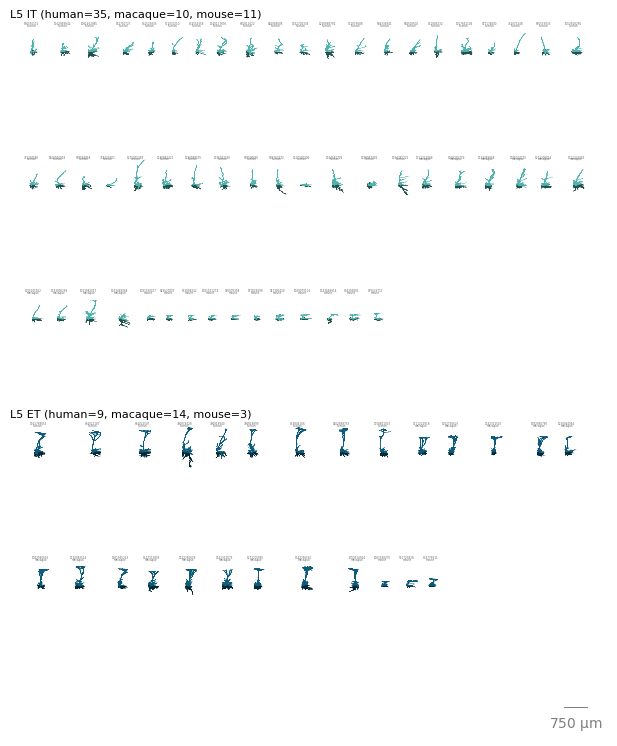

<Figure size 640x480 with 0 Axes>

In [42]:
#make pdf viewer

#formatting vars for tinkering 
group_title_start_height = 2700 #900 #starting height for group (e.g., region) title 
group_title_font_size = 8 #font size for group (e.g., region) title 

cell_title_start_height = 2300 #700 #starting height for cell title 
cell_title_vertical_space = 150 #150 #how much white space between rows of the cell title
cell_title_view_font_size = 4 #font size for cell 'xy', 'yz' view label

line_w = 0.1

#####

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    sps_list = list(sorted_cells.specimen_id.values)
    sps_list.reverse() #because we pop() off spc, which takes off the last value in the list. Reversing here keeps the plotting order consistent with the csv order.

    clust_id_set = set()
    failed_to_load = []

    print("Sps list is {} long".format(len(sps_list)))
    buffer=400
    with PdfPages(viewer_outfile) as pdf:
        while sps_list != []:
            fig, axes = plt.subplots(nrows=6,ncols=1,figsize=(7.5,10),sharex=True,sharey=True, gridspec_kw = {'wspace':0, 'hspace':0.3}) 
            for ax in axes: 

                ax.axis('off')
                ax.set_xlim(0,18100) 
                lim = 18000
                xloc = 0
                xoffset = 0
                ax.set_anchor('W')
                # ax.axhline(0, c="lightgrey",linewidth=0.50)

                while xloc < lim: #plot as many neurons as fit on this row
                    if sps_list != []:
                        sp = sps_list.pop() 
                        
                        # get data for this specimen
                        # subclass = sorted_cells[sorted_cells.specimen_id==sp][subclass_var_name].iloc[0]
                        clust_id = sorted_cells[sorted_cells.specimen_id==sp][cluster_var].iloc[0]
                        clust_len = len(sorted_cells[sorted_cells[cluster_var]==clust_id])

                        # cell title
                        sp_title = []
                        if 'title' in locals():
                            for t in title:
                                sp_title.append(str(sorted_cells[sorted_cells.specimen_id==sp][t].iloc[0]))
                        
                        # get plotting colors 
                        try:
                            # decide the colors for this cells axon, apical, and basal
                            if clust_id.startswith('L2/3 IT'):
                                hex_color = color_dict['L2/3 IT'][1:]
                            else:
                                hex_color = color_dict[clust_id][1:]

                            contrast_level = 0.45
                            lighter_color_rgb = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
                            darker_color_rgb = tuple([int((contrast_level*x)) for x in lighter_color_rgb])
                            grey_hex = '#8f8f8f'
                            dark_hex = '#%02x%02x%02x' % darker_color_rgb
                            hex_color = '#'+hex_color

                            cell_type_colors_dict = {3: dark_hex, 4: hex_color, 2: grey_hex}

                            #swap colors for axon-only plotting
                            if compartment_list == [1,2]: 
                                cell_type_colors_dict = {3: grey_hex, 4: grey_hex, 2: hex_color}
                        except: 
                            cell_type_colors_dict={1: 'black', 2: "firebrick", 4: "orange", 3: "steelblue"}
                        morph_colors = {k:v for k,v in cell_type_colors_dict.items() if k in compartment_list}


                        # cell_type_colors_dict={1: 'black', 2: "firebrick", 4: "orange", 3: "steelblue"}
                        # morph_colors = {k:v for k,v in cell_type_colors_dict.items() if k in compartment_list}
                        
                        # get the layer-aligned file
                        swc_pth = sorted_cells.SWC_upright[sorted_cells.specimen_id == sp].iloc[0]
                        nrn = morphology_from_swc(swc_pth)
                        nrn = normalize_position(nrn)

                        xoffset += leftextent(nrn,compartment_list)
                        if clust_id not in clust_id_set:
                            if xloc != 0:
                                sps_list = sps_list + [sp]
                                break

                            else:
                                #plot cell title
                                y = cell_title_start_height
                                i = 0
                                for l in sp_title:
                                    y-=cell_title_vertical_space
                                    ax.text(xoffset, y,l,horizontalalignment='center',fontsize=title_font_size[i], color="dimgrey")
                                    i+=1
                                    
                                #plot cell cluster info (e.g. ttype and num cells)
                                n_human = len(sorted_cells[(sorted_cells[cluster_var] == clust_id) & (sorted_cells['species'] == 'human')])
                                n_nhp = len(sorted_cells[(sorted_cells[cluster_var] == clust_id) & (sorted_cells['species'] == 'macaque')])
                                n_mouse = len(sorted_cells[(sorted_cells[cluster_var] == clust_id) & (sorted_cells['species'] == 'mouse')])
                                ax.text(-500,group_title_start_height, f"{clust_id} (human={n_human}, macaque={n_nhp}, mouse={n_mouse})",
                                horizontalalignment='left',fontsize=group_title_font_size, color='black') 

                                clust_id_set.add(clust_id)

                                y-=cell_title_vertical_space
                                for s in set_side:
                                    basic_morph_plot(nrn, morph_colors = morph_colors, ax = ax, xoffset = xoffset, side = s, line_w=line_w, 
                                                     scatter_roots = False, scatter_soma = False, plot_soma = False)
                                    xoffset += rightextent(nrn,compartment_list)
                                    xoffset += buffer       

                        else:
                            if xoffset+rightextent(nrn,compartment_list)+buffer>lim: #if gone over page width limit for this row, pop cell back on list and go to next plotting row
                                sps_list = sps_list + [sp]
                                break
                            else:
                                
                                clust_id_set.add(clust_id)
                                y = cell_title_start_height #plot cell title 
                                i = 0
                                for l in sp_title:
                                    y-=cell_title_vertical_space
                                    ax.text(xoffset, y,l,horizontalalignment='center',fontsize=title_font_size[i], color="dimgrey")
                                    i+=1

                                y-=cell_title_vertical_space
                                for s in set_side:
                                    basic_morph_plot(nrn, morph_colors = morph_colors, ax = ax, xoffset = xoffset, side = s, line_w=line_w, 
                                                     scatter_roots = False, scatter_soma = False, plot_soma = False)
                                    xoffset += rightextent(nrn,compartment_list)
                                    xoffset += buffer                            

                        xloc=xoffset

                    else:
                        break

            #add a scale bar 
            scalebar = ScaleBar(1, "um", location='lower right', frameon=False, length_fraction=0.05, color='grey')
            ax.add_artist(scalebar)

            for ax in axes:
                ax.set_aspect("equal")
                if stretch_z:
                    ax.set_aspect(1 / 2.5)
            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600)
    plt.show()
    plt.clf()
    print()


Gallery viewer - one per group per species

In [13]:
import json 
from morph_utils.templates import load_layer_template 

In [14]:
species_data_dir = DATA_ROOT / 'species_comparison' / 'gallery_cells' / '20260828'


color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

macaque_average_layers_file =   DATA_ROOT / 'macaque' / 'average_cortical_layers' / '20250314' / 'macaque_average_layers.json'



Gallery layer aligned - to pia 

In [15]:
gallery_type = 'species' #'primate' 

if gallery_type == 'primate': cluster_var_name = cluster_col
else: cluster_var_name = subclass_col

title = ['species'] 
title_font_size = [6]

#get data 
data = pd.read_csv(os.path.join(species_data_dir, f'{gallery_type}_gallery_cells.csv'))
data = data.merge(sorted_cells[['specimen_id', 'SWC_upright', 'SWC_layer_aligned']], how='left', on='specimen_id')

viewer_outfile = os.path.join(OUT_DIR, f'{gallery_type}_gallery_layer_aligned.pdf')

#colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))

#Get L1 boundary
human_layers, _, _ = load_layer_template('human')
with open(macaque_average_layers_file, "r") as file:
    macaque_layers = json.load(file)
mouse_layers, _, _ = load_layer_template('mouse')

species_l1 = {
    'human' : human_layers['2'], 
    'macaque' : macaque_layers['2'],
    'mouse' :  mouse_layers['2/3']
}

Sps list is 27 long


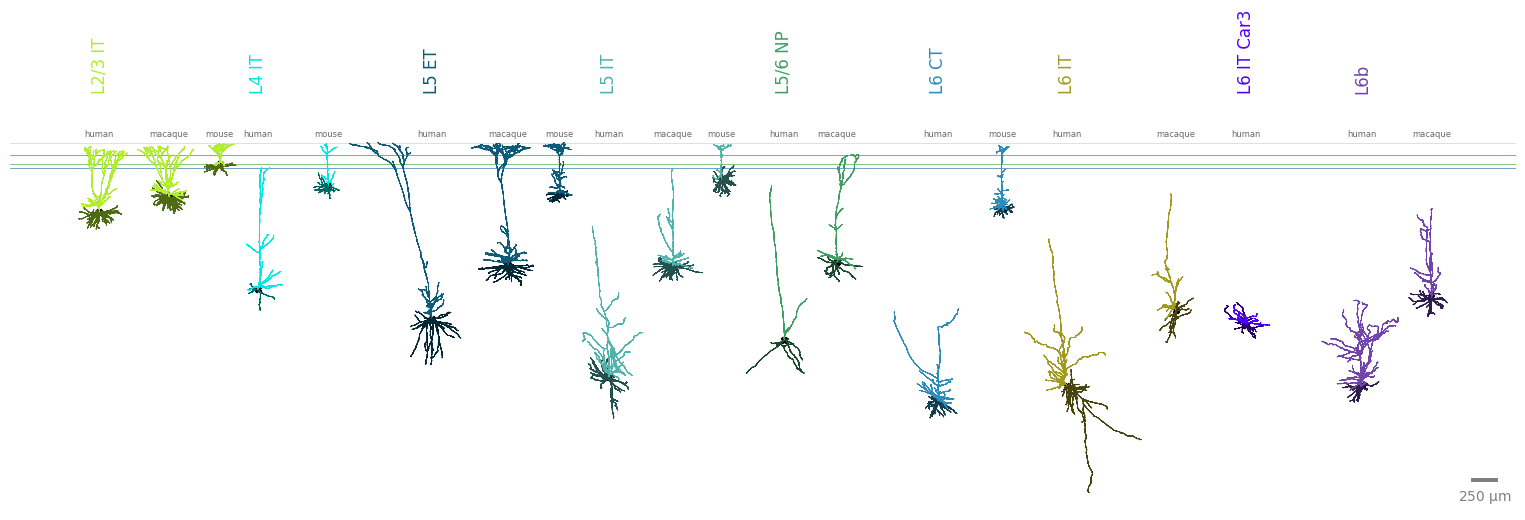

<Figure size 640x480 with 0 Axes>

In [16]:
#make pdf viewer

#formatting vars for tinkering 
group_title_start_height = 500 #100 #starting height for group (e.g., region) title 
group_title_font_size = 12 #font size for group (e.g., region) title 

cell_title_start_height = 200 #700 #starting height for cell title 
cell_title_vertical_space = 150 #how much white space between rows of the cell title
cell_title_view_font_size = 6 #font size for cell 'xy', 'yz' view label

#####

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)


    sps_list = list(data.specimen_id.values)
    sps_list.reverse() #because we pop() off spc, which takes off the last value in the list. Reversing here keeps the plotting order consistent with the csv order.

    clust_id_set = set()
    failed_to_load = []

    print("Sps list is {} long".format(len(sps_list)))
    buffer=100
    with PdfPages(viewer_outfile) as pdf:
        #one fig per page, each has page (fig) has 8 rows. 
        fig, ax = plt.subplots(nrows=1,ncols=1, figsize=(50, 5),sharex=True,sharey=True, gridspec_kw = {'wspace':0, 'hspace':0.3}) #gridspec_kw = {'wspace':0, 'hspace':0},

        ax.axis('off')
        xoffset = 0
        ax.set_anchor('W')
        ax.axhline(0, c="lightgrey",linewidth=0.50)

        for species, l1_depth in species_l1.items():
            ax.axhline(-l1_depth, c=species_colors[species],linewidth=0.50)
        
        while sps_list != []:
            if sps_list != []:
                sp = sps_list.pop() #the specimen to plot

                if sp == 0:
                    xoffset += buffer*2
                    continue
                
                # get data for this specimen
                clust_id = data[data.specimen_id==sp]['GA_subclass'].iloc[0]

                # cell title
                sp_title = []
                if sp != 0:
                    if 'title' in locals():
                        for t in title:
                            sp_title.append(str(data[data.specimen_id==sp][t].iloc[0]))

                try:
                    ## decide the colors for this cells axon, apical, and basal
                    if clust_id.startswith('L2/3 IT'):
                        hex_color = color_dict['L2/3 IT'][1:]
                    else:
                        hex_color = color_dict[clust_id][1:]
                    contrast_level = 0.45
                    lighter_color_rgb = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
                    darker_color_rgb = tuple([int((contrast_level*x)) for x in lighter_color_rgb])
                    grey_hex = '#8f8f8f'
                    dark_hex = '#%02x%02x%02x' % darker_color_rgb
                    hex_color = '#'+hex_color

                    cell_type_colors_dict = {3: dark_hex, 4: hex_color, 2: grey_hex}
                    
                    if compartment_list == [1,2]: cell_type_colors_dict = {3: grey_hex, 4: grey_hex, 2: hex_color} #for axon only plotting

                except: 
                    cell_type_colors_dict={1: 'black', 2: "firebrick", 4: "orange", 3: "steelblue"}
                
                morph_colors = {k:v for k,v in cell_type_colors_dict.items() if k in compartment_list}

            
                # get the layer-aligned file
                swc_pth = data.SWC_layer_aligned[data.specimen_id == sp].iloc[0]
                nrn = morphology_from_swc(swc_pth)
                # nrn = normalize_position(nrn)

                xoffset += leftextent(nrn,compartment_list)


                if clust_id not in clust_id_set:

                    #plot cell cluster info (e.g. ttype and num cells)
                    ax.text(xoffset,group_title_start_height,
                    "{}".format(clust_id),
                    horizontalalignment='center',fontsize=group_title_font_size, color=hex_color, rotation=90) 

                    clust_id_set.add(clust_id)

                    if sp != 0 :
                        for s in set_side:
                            basic_morph_plot(nrn,morph_colors=morph_colors, 
                                        ax=ax, xoffset=xoffset,side=s)
                            xoffset += rightextent(nrn,compartment_list)
                            xoffset += buffer       
                    else:
                        plt.plot(xoffset, 0, marker='x', color='grey')  
                        xoffset += buffer*3
                    

                else:
                        
                    clust_id_set.add(clust_id)

                    if sp != 0 :
                        for s in set_side:
                            basic_morph_plot(nrn,morph_colors=morph_colors, 
                                        ax=ax, xoffset=xoffset,side=s)
                            xoffset += rightextent(nrn,compartment_list)
                        xoffset += buffer
                    else:
                        plt.plot(xoffset, 0, marker='x', color='grey') 
                        xoffset += buffer*3

                y = cell_title_start_height #plot cell title 
                for i, l in enumerate(sp_title):
                    y-=cell_title_vertical_space
                    ax.text(xoffset-buffer-rightextent(nrn,compartment_list), y,l,horizontalalignment='center',fontsize=title_font_size[i], color="dimgrey")

        #add scale bar at the end 
        scalebar = ScaleBar(1, "um", location='lower right', frameon=False, fixed_value=250,  color='grey')
        ax.add_artist(scalebar)

        ax.set_aspect("equal")
        fig.subplots_adjust(wspace=0, hspace=0.0)
        pdf.savefig(dpi=600, bbox_inches='tight')
    plt.show()
    plt.clf()
    print()
